# Differential protein abundance with limma: PR1 heart valve disease

Data: Nordmeyer et al. 2023 (*Life Science Alliance*, PXD023800). Left-ventricle biopsies from 41 aortic stenosis (AS), 17 mitral regurgitation (MR) and 17 control donor hearts (CON). Input: `PR1_processed_data.xlsx` (filtered, log2, median-normalized, Perseus-imputed; made by the QC notebook).

**What this notebook does**
1. Explains what limma does, in plain words.
2. Shows that the variance differs a lot between the groups.
3. Fits limma the way the paper did: one linear model per protein over all samples, empirical Bayes variance moderation with a mean–variance trend (`eBayes(trend = TRUE)`), Benjamini–Hochberg correction, significant if adjusted p < 0.05.
4. Compares the **disease groups** (AS vs CON, MR vs CON, AS vs MR) and sorts the hits into shared / AS-specific / MR-specific / divergent, as in the paper.
5. Compares the **sexes**: disease vs control within each sex (as in the paper), female vs male within each group, and a formal test of whether the disease effect differs between the sexes (interaction).
6. Summarizes how many proteins differ between groups and sexes.

There are no covariates (age, medication, batch) in the data, so, like the paper, the model contains only disease group and sex.

**How to run:** open in VS Code or Jupyter, select the **R** kernel, *Run All*.

## 1. What limma does, in plain words

**One model per protein, using all samples at once.** For every protein separately, limma fits one linear model to the log2 values of all 75 patients. The model only knows which group each patient belongs to, so the "fit" simply gives the **average (arithmetic mean of the log2 values) of every group**, plus one estimate of how much patients vary around their group average. That variability estimate uses all 75 patients together (pooled), which makes it more stable than estimating it from 5 or 8 patients alone. This is repeated for all ~3,800 proteins.

**Contrasts = questions asked to the fitted model.** After fitting, we ask: *is the AS average different from the CON average?* The answer is a log2 fold change (difference of the two averages) and a t-statistic (difference ÷ its uncertainty). All comparisons are read from the same fit; the model is not refitted per comparison.

**Empirical Bayes: borrowing information across proteins.** With few patients per group, some proteins get a variance estimate that is too small just by chance; they would look highly significant even for tiny differences. limma looks at the variances of *all* proteins and pulls each protein's variance part of the way towards what is typical. Extreme small variances go up, extreme large ones go down. This gives the **moderated t-statistic**: like a t-test, but more reliable with small groups.

**Trend.** In mass spectrometry, low-abundance proteins are noisier than high-abundance ones. With `trend = TRUE`, each protein is pulled towards the typical variance *of proteins with a similar intensity*, not towards one global value.

**Multiple testing.** About 3,800 proteins are tested per comparison, so ~190 would reach p < 0.05 by pure chance. P-values are therefore adjusted with **Benjamini–Hochberg** (false discovery rate). A protein counts as significant when the adjusted p-value is < 0.05.

```
for each protein:   all 75 samples -> one linear model -> group means + pooled variance
across proteins:    variances shrunk towards the intensity-dependent typical value (eBayes, trend)
for each contrast:  difference of means / moderated SE -> moderated t -> p -> BH-adjusted p
```

## 2. Packages and settings

limma comes from Bioconductor, readxl from CRAN. They are installed only if missing.

In [1]:
if (!requireNamespace("BiocManager", quietly = TRUE)) install.packages("BiocManager")
if (!requireNamespace("limma", quietly = TRUE)) BiocManager::install("limma", update = FALSE)
if (!requireNamespace("readxl", quietly = TRUE)) install.packages("readxl")

library(limma)
library(readxl)

DATA_FILE <- "PR1_processed_data.xlsx"   # same folder as this notebook

FDR_CUTOFF <- 0.05                       # adjusted p-value cut-off (as in the paper)

# colours (same as in the QC notebook)
COND_COL <- c(CON = "#009E73", AS = "#D55E00", MR = "#0072B2")

options(repr.plot.width = 12, repr.plot.height = 6, width = 160)
cat("limma version:", as.character(packageVersion("limma")), "\n")

limma version: 3.58.1 


## 3. Load the data

- `imputed`: the matrix limma uses (as in the paper, missing values were filled in with the Perseus method).
- `imputed_mask`: TRUE where a value was imputed; used later to check that the results are not only driven by imputation.
- `sample_qc`: group and sex for every sample.

Some gene names occur more than once (different protein groups of the same gene), so every row gets a unique label (`Gene names`, first entry, made unique).

In [2]:
imp  <- as.data.frame(read_excel(DATA_FILE, sheet = "imputed"))
mask <- as.data.frame(read_excel(DATA_FILE, sheet = "imputed_mask"))
qc   <- as.data.frame(read_excel(DATA_FILE, sheet = "sample_qc"))

samples <- qc$sample
stopifnot(all(samples %in% names(imp)))

# protein annotation + unique row labels
gene <- sub(";.*", "", imp$`Gene names`)
gene[is.na(gene) | gene == ""] <- sub(";.*", "", imp$`Majority protein IDs`[is.na(gene) | gene == ""])
label <- make.unique(gene, sep = "_")
annot <- data.frame(protein = label,
                    gene_names = imp$`Gene names`,
                    protein_ids = imp$`Majority protein IDs`,
                    protein_names = imp$`Protein names`,
                    n_imputed = imp$n_imputed_values,
                    single_peptide = imp$single_peptide,
                    row.names = label, check.names = FALSE)

# expression matrix: proteins x samples (log2, normalized, imputed)
expr <- as.matrix(imp[, samples]);  rownames(expr) <- label
is_imp <- as.matrix(mask[, samples]); rownames(is_imp) <- label

# sample information
cond <- c("control (donor heart)" = "CON", "aortic stenosis" = "AS",
          "mitral regurgitation" = "MR")[qc$group]
sex  <- ifelse(qc$sex == "female", "F", "M")
info <- data.frame(sample = samples,
                   condition = factor(cond, levels = c("CON", "AS", "MR")),
                   sex = factor(sex, levels = c("F", "M")))
info$cell <- factor(paste(info$condition, info$sex, sep = "_"),
                    levels = c("CON_F", "CON_M", "AS_F", "AS_M", "MR_F", "MR_M"))

cat(nrow(expr), "proteins x", ncol(expr), "samples\n")
cat("Imputed values:", round(100 * mean(is_imp), 1), "% of the matrix\n\n")
print(table(condition = info$condition, sex = info$sex))

3834 proteins x 75 samples


Imputed values: 10.3 % of the matrix



         sex
condition  F  M
      CON  8  9
      AS  21 20
      MR   5 12


## 4. The variance differs a lot between the groups

Standard limma assumes that, for a given protein, patients scatter equally much around the mean in every group (one pooled variance). Here we check that assumption by computing, for each protein, the standard deviation (SD) **within each of the six subgroups** (condition × sex).

Three views:
- **Boxplot** of the per-protein SDs per subgroup.
- **Ratio** SD(AS) / SD(CON) and SD(MR) / SD(CON) per protein: values > 1 mean the disease group is more variable.
- **Global test across proteins**: paired Wilcoxon test of SD(AS) vs SD(CON) over all proteins. This asks whether AS is *systematically* more variable.
- **Brown–Forsythe test** per protein (a robust Levene test: ANOVA on the absolute distances from the group median), BH-corrected: for how many *individual* proteins can a variance difference be shown?

Imputed values all sit in a narrow band at the low end and could inflate or deflate SDs, so the numbers are also shown for proteins **without any imputed value**.

      n_patients median_SD_all median_SD_no_imp
CON_F          8         0.520            0.357
CON_M          9         0.553            0.329
AS_F          21         0.859            0.456
AS_M          20         0.782            0.408
MR_F           5         0.624            0.396
MR_M          12         0.716            0.411



Proteins without imputed values: 1758 


Share of proteins where SD(AS) > SD(CON): 70.9 % (all) | 71.5 % (no imputed)


Median SD ratio AS/CON: 1.21 | MR/CON: 1.14 


Global paired Wilcoxon over proteins: SD(AS) vs SD(CON) p = 1.8e-163 | SD(MR) vs SD(CON) p = 8e-88 


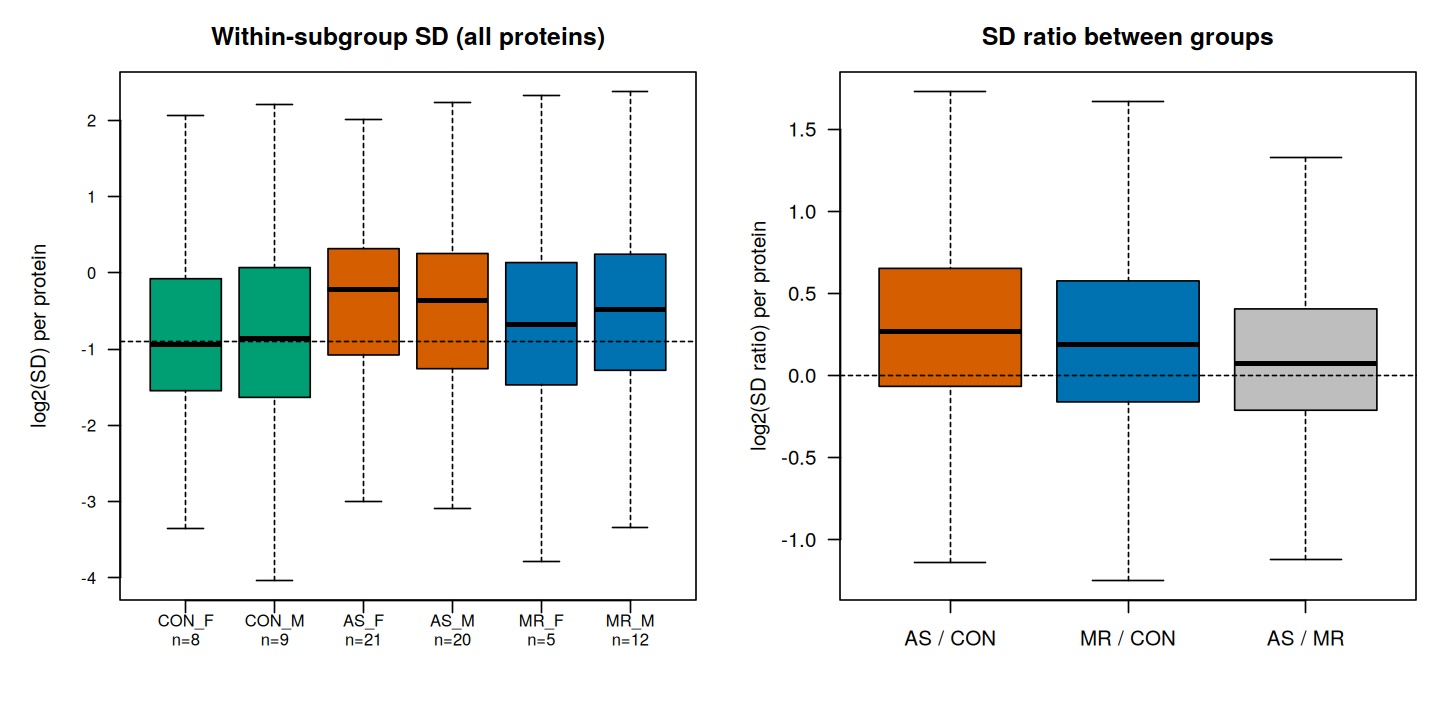

In [3]:
sd_by <- function(fac) sapply(levels(fac), function(l) apply(expr[, fac == l, drop = FALSE], 1, sd))
sd_cell <- sd_by(info$cell)
sd_cond <- sd_by(info$condition)
no_imp  <- rowSums(is_imp) == 0          # proteins without any imputed value

par(mfrow = c(1, 2), mar = c(5, 5, 3, 1))
boxplot(log2(sd_cell), col = rep(COND_COL, each = 2), outline = FALSE,
        ylab = "log2(SD) per protein", main = "Within-subgroup SD (all proteins)",
        names = paste0(colnames(sd_cell), "\nn=", table(info$cell)), las = 1, cex.axis = 0.8)
abline(h = median(log2(sd_cell[, c("CON_F", "CON_M")])), lty = 2)

ratio <- cbind("AS / CON" = sd_cond[, "AS"] / sd_cond[, "CON"],
               "MR / CON" = sd_cond[, "MR"] / sd_cond[, "CON"],
               "AS / MR"  = sd_cond[, "AS"] / sd_cond[, "MR"])
boxplot(log2(ratio), outline = FALSE, col = c(COND_COL["AS"], COND_COL["MR"], "grey"),
        ylab = "log2(SD ratio) per protein", main = "SD ratio between groups", las = 1)
abline(h = 0, lty = 2)

# summary table
var_summary <- data.frame(
  n_patients        = as.vector(table(info$cell)),
  median_SD_all     = round(apply(sd_cell, 2, median), 3),
  median_SD_no_imp  = round(apply(sd_cell[no_imp, ], 2, median), 3))
print(var_summary)
cat("\nProteins without imputed values:", sum(no_imp), "\n")
cat("Share of proteins where SD(AS) > SD(CON):",
    round(100 * mean(ratio[, 1] > 1), 1), "% (all) |",
    round(100 * mean(ratio[no_imp, 1] > 1), 1), "% (no imputed)\n")
cat("Median SD ratio AS/CON:", round(median(ratio[, 1]), 2),
    "| MR/CON:", round(median(ratio[, 2]), 2), "\n")
cat("Global paired Wilcoxon over proteins: SD(AS) vs SD(CON) p =",
    signif(wilcox.test(sd_cond[, "AS"], sd_cond[, "CON"], paired = TRUE)$p.value, 2),
    "| SD(MR) vs SD(CON) p =",
    signif(wilcox.test(sd_cond[, "MR"], sd_cond[, "CON"], paired = TRUE)$p.value, 2), "\n")

In [4]:
# Brown-Forsythe test per protein: one-way ANOVA on |value - group median|
bf_p <- apply(expr, 1, function(y) {
  z <- abs(y - ave(y, info$condition, FUN = median))
  anova(lm(z ~ info$condition))[["Pr(>F)"]][1]
})
bf_adj <- p.adjust(bf_p, "BH")
cat("Proteins with significantly different variance between CON / AS / MR (BH < 0.05):\n")
cat("  all proteins:        ", sum(bf_adj < 0.05), "of", length(bf_adj),
    sprintf("(%.1f%%)\n", 100 * mean(bf_adj < 0.05)))
cat("  no imputed values:   ", sum(bf_adj[no_imp] < 0.05), "of", sum(no_imp),
    sprintf("(%.1f%%)\n", 100 * mean(bf_adj[no_imp] < 0.05)))
# which group is the most variable for these proteins?
most_var <- colnames(sd_cond)[apply(sd_cond[bf_adj < 0.05, , drop = FALSE], 1, which.max)]
cat("  most variable group among them:\n"); print(table(most_var))

Proteins with significantly different variance between CON / AS / MR (BH < 0.05):


  all proteins:         9 of 3834 (0.2%)


  no imputed values:    6 of 1758 (0.3%)


  most variable group among them:


most_var
 AS CON  MR 
  1   6   2 


**Reading it.** If the SDs were equal, the boxes would sit at the same height and the ratio boxes would be centred on 0.
- The median within-group SD is about 0.52–0.55 in controls, 0.78–0.86 in AS and 0.62–0.72 in MR. AS is more variable than CON for about 71 % of proteins (median ratio 1.21), and MR is more variable than CON for most proteins too (median ratio 1.14). The global tests are extremely significant, and the pattern is the same for proteins without any imputed value, so it is not an imputation artefact. This matches the PCA and the paper's remark that AS shows higher within-group variability.
- The per-protein Brown–Forsythe test finds only a handful of proteins. That is not a contradiction: detecting a variance difference for *one* protein with 17 controls needs a very large difference. Here the difference is moderate but affects almost all proteins.

**Why it matters:** limma pools the variance over all groups. With unequal variances, the pooled value is too large for the calm control group and too small for the noisy AS group. Section 10a therefore repeats the analysis with **group-specific weights** (`arrayWeights`).

## 5. Design matrix: one mean per condition × sex cell

The model has six groups (cells): CON_F, CON_M, AS_F, AS_M, MR_F, MR_M. With `~ 0 + cell` every column of the design matrix is a 0/1 indicator for one cell, so each coefficient is simply the mean of that cell. Every patient has exactly one 1 in their row.

One model with six cells lets us answer all questions (groups, sexes, interaction) from **one fit** with **one** variance estimate per protein.

**Group comparisons, balanced for sex.** The sex ratio differs between the groups (MR: 5 F / 12 M). If we simply pooled everyone, "AS vs MR" would partly be a male vs female comparison. We therefore define the disease mean as the average of the female and male cell means, e.g. AS = (AS_F + AS_M) / 2. The paper does not state its exact design; this is the more careful choice when sex ratios differ.

In [5]:
design <- model.matrix(~ 0 + cell, data = info)
colnames(design) <- levels(info$cell)
cat("Design matrix, first rows (each row = one patient):\n")
print(head(design, 4))
cat("\nPatients per cell:\n"); print(colSums(design))

Design matrix, first rows (each row = one patient):


  CON_F CON_M AS_F AS_M MR_F MR_M
1     0     1    0    0    0    0
2     0     1    0    0    0    0
3     0     1    0    0    0    0
4     0     1    0    0    0    0



Patients per cell:


CON_F CON_M  AS_F  AS_M  MR_F  MR_M 
    8     9    21    20     5    12 


### Check: the coefficients are just the group means

For one protein, the limma coefficients equal the arithmetic means of the log2 values per cell computed by hand.

In [6]:
fit <- lmFit(expr, design)
p <- "COL1A1"
if (!p %in% rownames(expr)) p <- rownames(expr)[1]
by_hand <- tapply(expr[p, ], info$cell, mean)
print(round(rbind(limma_coefficient = fit$coefficients[p, ], mean_by_hand = by_hand), 4))

                  CON_F   CON_M    AS_F    AS_M    MR_F    MR_M
limma_coefficient 31.23 31.3688 33.1502 33.0081 32.5759 31.9898
mean_by_hand      31.23 31.3688 33.1502 33.0081 32.5759 31.9898


## 6. Contrasts: the questions we ask

| Family | Contrast | Meaning |
|---|---|---|
| **Groups** (as paper) | AS_vs_CON, MR_vs_CON, AS_vs_MR | disease comparisons, averaged over sex |
| **Disease vs control within each sex** (as paper) | AS_vs_CON_F, AS_vs_CON_M, MR_vs_CON_F, MR_vs_CON_M | e.g. female AS vs female controls |
| **Female vs male within each group** | F_vs_M_CON, F_vs_M_AS, F_vs_M_MR | sex differences inside one group |
| **Interaction** (not in paper) | AS_sexdiff, MR_sexdiff | is the disease effect different in women and men? (AS_F − CON_F) − (AS_M − CON_M) |

Positive log2FC = higher in the first-named group (for F_vs_M: higher in women; for the interaction: the disease effect is more positive in women).

In [7]:
cm <- makeContrasts(
  AS_vs_CON   = (AS_F + AS_M) / 2 - (CON_F + CON_M) / 2,
  MR_vs_CON   = (MR_F + MR_M) / 2 - (CON_F + CON_M) / 2,
  AS_vs_MR    = (AS_F + AS_M) / 2 - (MR_F + MR_M) / 2,
  AS_vs_CON_F = AS_F - CON_F,
  AS_vs_CON_M = AS_M - CON_M,
  MR_vs_CON_F = MR_F - CON_F,
  MR_vs_CON_M = MR_M - CON_M,
  F_vs_M_CON  = CON_F - CON_M,
  F_vs_M_AS   = AS_F - AS_M,
  F_vs_M_MR   = MR_F - MR_M,
  AS_sexdiff  = (AS_F - CON_F) - (AS_M - CON_M),
  MR_sexdiff  = (MR_F - CON_F) - (MR_M - CON_M),
  levels = design)
print(t(cm))

             Levels
Contrasts     CON_F CON_M AS_F AS_M MR_F MR_M
  AS_vs_CON    -0.5  -0.5  0.5  0.5  0.0  0.0
  MR_vs_CON    -0.5  -0.5  0.0  0.0  0.5  0.5
  AS_vs_MR      0.0   0.0  0.5  0.5 -0.5 -0.5
  AS_vs_CON_F  -1.0   0.0  1.0  0.0  0.0  0.0
  AS_vs_CON_M   0.0  -1.0  0.0  1.0  0.0  0.0
  MR_vs_CON_F  -1.0   0.0  0.0  0.0  1.0  0.0
  MR_vs_CON_M   0.0  -1.0  0.0  0.0  0.0  1.0
  F_vs_M_CON    1.0  -1.0  0.0  0.0  0.0  0.0
  F_vs_M_AS     0.0   0.0  1.0 -1.0  0.0  0.0
  F_vs_M_MR     0.0   0.0  0.0  0.0  1.0 -1.0
  AS_sexdiff   -1.0   1.0  1.0 -1.0  0.0  0.0
  MR_sexdiff   -1.0   1.0  0.0  0.0  1.0 -1.0


## 7. Fit, empirical Bayes moderation and the mean–variance trend

`contrasts.fit` turns the six cell means into the contrasts; `eBayes(trend = TRUE)` moderates the variances.

Two plots:
- **Left (`plotSA`)**: each point is one protein, x = average intensity, y = its own (unmoderated) residual SD. The blue line is the fitted trend. If it slopes, `trend = TRUE` is justified.
- **Right**: each protein's own SD vs the moderated SD after eBayes. Points above the red diagonal were pulled up, points below were shrunk down. The further the cloud deviates from the diagonal, the stronger the borrowing.

Prior degrees of freedom (strength of borrowing, in 'extra samples'): 4.2 


Residual degrees of freedom per protein: 69 


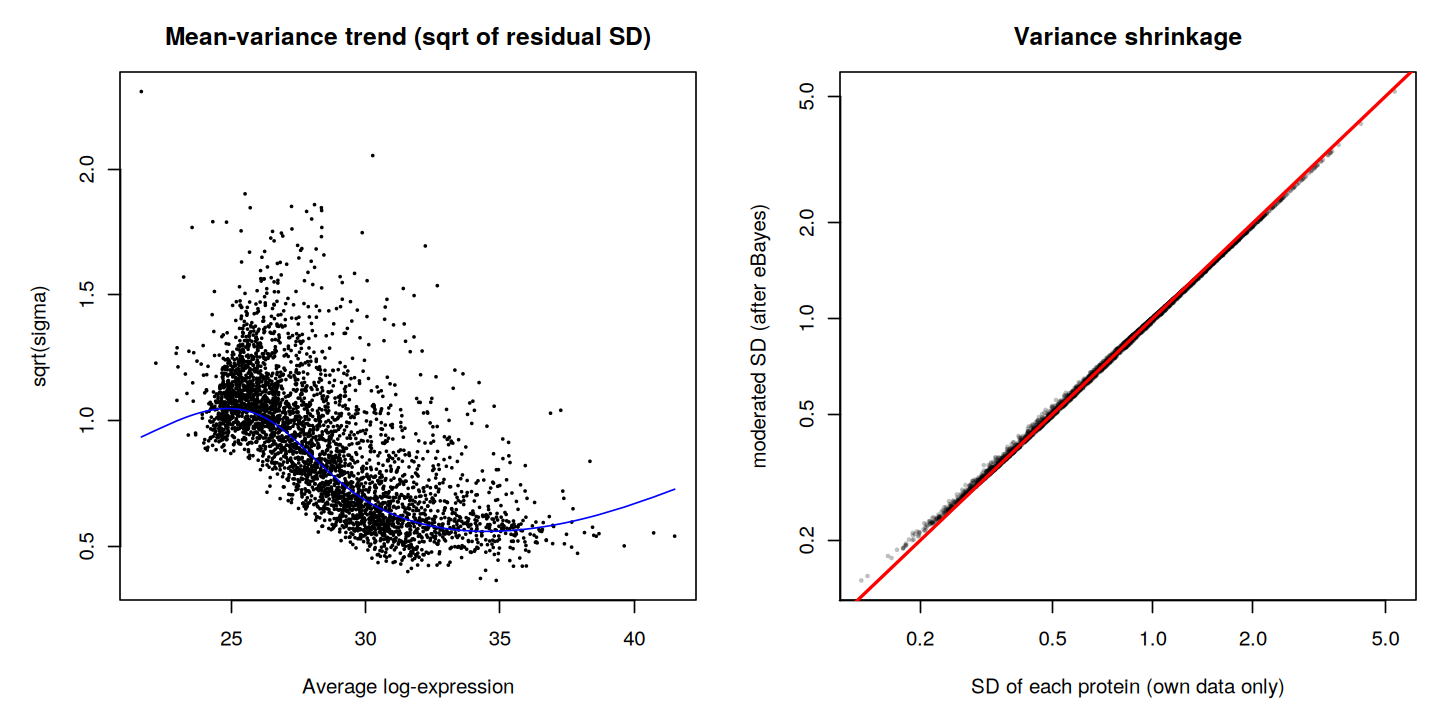

In [8]:
fit2 <- contrasts.fit(fit, cm)
fit2 <- eBayes(fit2, trend = TRUE)

par(mfrow = c(1, 2), mar = c(5, 5, 3, 1))
plotSA(fit2, main = "Mean-variance trend (sqrt of residual SD)")
plot(fit2$sigma, sqrt(fit2$s2.post), pch = 16, cex = 0.4, col = "#00000040",
     xlab = "SD of each protein (own data only)", ylab = "moderated SD (after eBayes)",
     main = "Variance shrinkage", log = "xy")
abline(0, 1, col = "red", lwd = 2)

cat("Prior degrees of freedom (strength of borrowing, in 'extra samples'):",
    round(median(fit2$df.prior), 1), "\n")
cat("Residual degrees of freedom per protein:", fit2$df.residual[1], "\n")

**Interpretation.**
- **Trend (left):** the SD clearly depends on intensity: low-abundance proteins (log2 ≈ 25) are about twice as noisy as abundant ones (≈ 33). That is why `trend = TRUE` is used: each protein is compared with proteins of similar intensity.
- **Shrinkage (right):** the points lie almost on the diagonal, so moderation changes the variances only slightly here. The reason is in the numbers above: each protein already has 69 residual degrees of freedom of its own (75 samples − 6 means), and borrowing adds only ~4 more. eBayes matters most with small experiments (e.g. 3 vs 3 samples). With 75 samples it is a small safety net, and the results are close to ordinary t-tests with a pooled variance. The very low SDs at the bottom left are pulled up the most, which is exactly the protection against "too good to be true" proteins.

## 8. Results per contrast

`topTable` returns, for every protein: `logFC` (difference of the means, log2), `AveExpr`, `t` (moderated t), `P.Value`, `adj.P.Val` (Benjamini–Hochberg, separately per contrast as in the paper) and `B`. A protein is called significant at `adj.P.Val < 0.05`; no fold-change cut-off (as in the paper).

For each result we also add how many imputed values the protein has in the two compared groups (`imputed_in_groups`), so hits driven by imputation can be spotted.

In [9]:
# which cells take part in each contrast (for counting imputed values)
cells_of <- function(cn) names(which(cm[, cn] != 0))

res <- lapply(colnames(cm), function(cn) {
  tt <- topTable(fit2, coef = cn, number = Inf, sort.by = "none", adjust.method = "BH")
  used <- info$cell %in% cells_of(cn)
  out <- data.frame(annot[rownames(tt), c("protein", "gene_names", "protein_ids", "protein_names")],
                    logFC = tt$logFC, AveExpr = tt$AveExpr, t = tt$t,
                    P.Value = tt$P.Value, adj.P.Val = tt$adj.P.Val,
                    imputed_in_groups = rowSums(is_imp[rownames(tt), used, drop = FALSE]),
                    single_peptide = annot[rownames(tt), "single_peptide"],
                    check.names = FALSE)
  out$direction <- ifelse(out$adj.P.Val < FDR_CUTOFF, ifelse(out$logFC > 0, "up", "down"), "ns")
  out[order(out$P.Value), ]
})
names(res) <- colnames(cm)

# decideTests: -1 / 0 / +1 per protein and contrast (BH per contrast)
dt <- decideTests(fit2, method = "separate", adjust.method = "BH", p.value = FDR_CUTOFF)
as_mat <- function(x) matrix(as.numeric(x), nrow(x), dimnames = dimnames(x))  # plain matrix
dt <- as_mat(dt)

counts <- data.frame(contrast = colnames(dt),
                     up   = colSums(dt ==  1),
                     down = colSums(dt == -1),
                     total = colSums(dt != 0), row.names = NULL)
counts$family <- c(rep("groups", 3), rep("disease vs control within sex", 4),
                   rep("female vs male within group", 3), rep("interaction (sex x disease)", 2))
counts

contrast,up,down,total,family
<chr>,<dbl>,<dbl>,<dbl>,<chr>
AS_vs_CON,560,723,1283,groups
MR_vs_CON,237,234,471,groups
AS_vs_MR,296,239,535,groups
AS_vs_CON_F,344,360,704,disease vs control within sex
AS_vs_CON_M,288,280,568,disease vs control within sex
MR_vs_CON_F,68,64,132,disease vs control within sex
MR_vs_CON_M,65,42,107,disease vs control within sex
F_vs_M_CON,1,0,1,female vs male within group
F_vs_M_AS,2,1,3,female vs male within group


### Volcano plots

x = log2 fold change, y = −log10(adjusted p). Coloured = significant (adj. p < 0.05). The 10 most significant proteins are labelled.

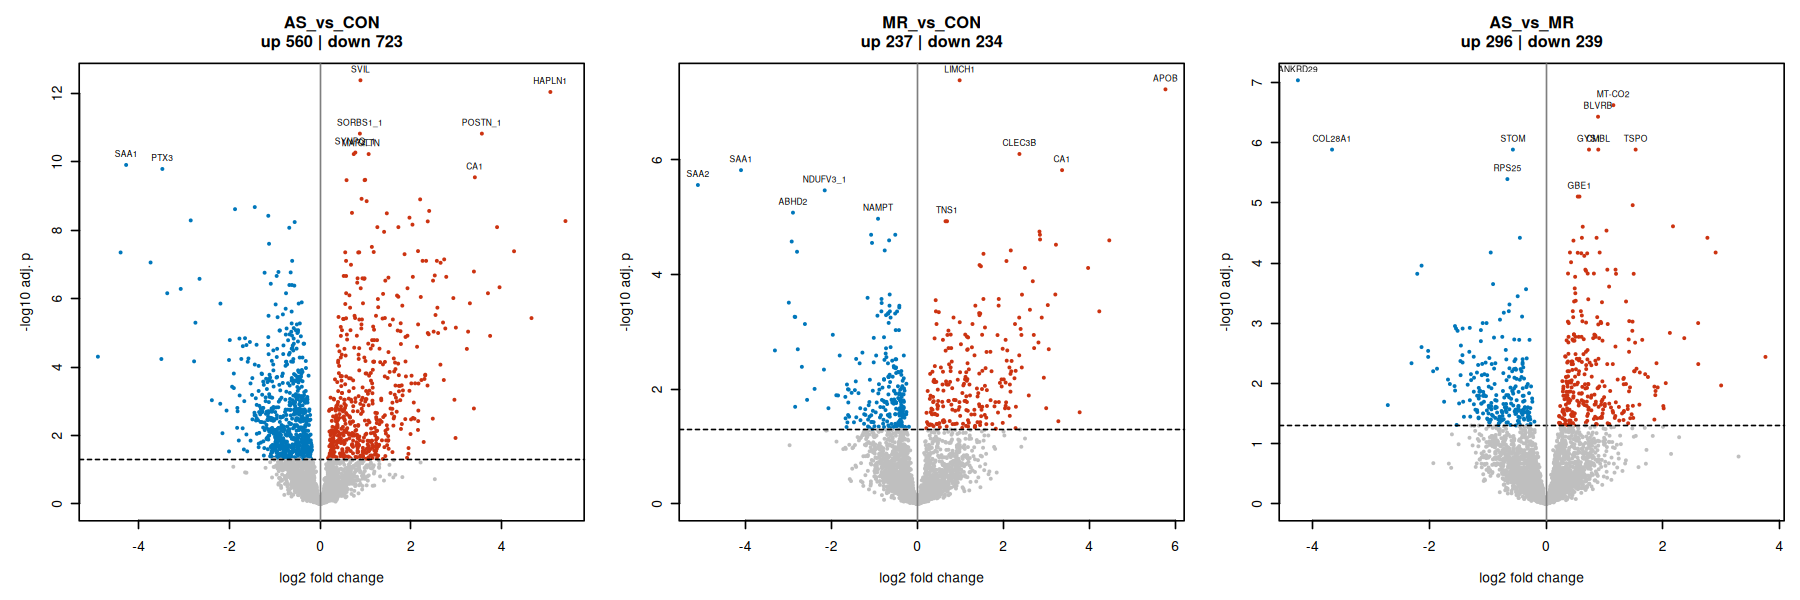

In [10]:
volcano <- function(cn, n_lab = 10) {
  r <- res[[cn]]
  y <- -log10(r$adj.P.Val)
  col <- ifelse(r$direction == "up", "#CC3311", ifelse(r$direction == "down", "#0077BB", "grey75"))
  plot(r$logFC, y, pch = 16, cex = 0.5, col = col, xlab = "log2 fold change",
       ylab = "-log10 adj. p", main = sprintf("%s\nup %d | down %d", cn,
       sum(r$direction == "up"), sum(r$direction == "down")))
  abline(h = -log10(FDR_CUTOFF), lty = 2); abline(v = 0, col = "grey50")
  top <- head(r[r$direction != "ns", ], n_lab)
  if (nrow(top)) text(top$logFC, -log10(top$adj.P.Val), top$protein, cex = 0.6, pos = 3)
}
options(repr.plot.width = 15, repr.plot.height = 5)
par(mfrow = c(1, 3), mar = c(5, 5, 4, 1))
for (cn in c("AS_vs_CON", "MR_vs_CON", "AS_vs_MR")) volcano(cn)

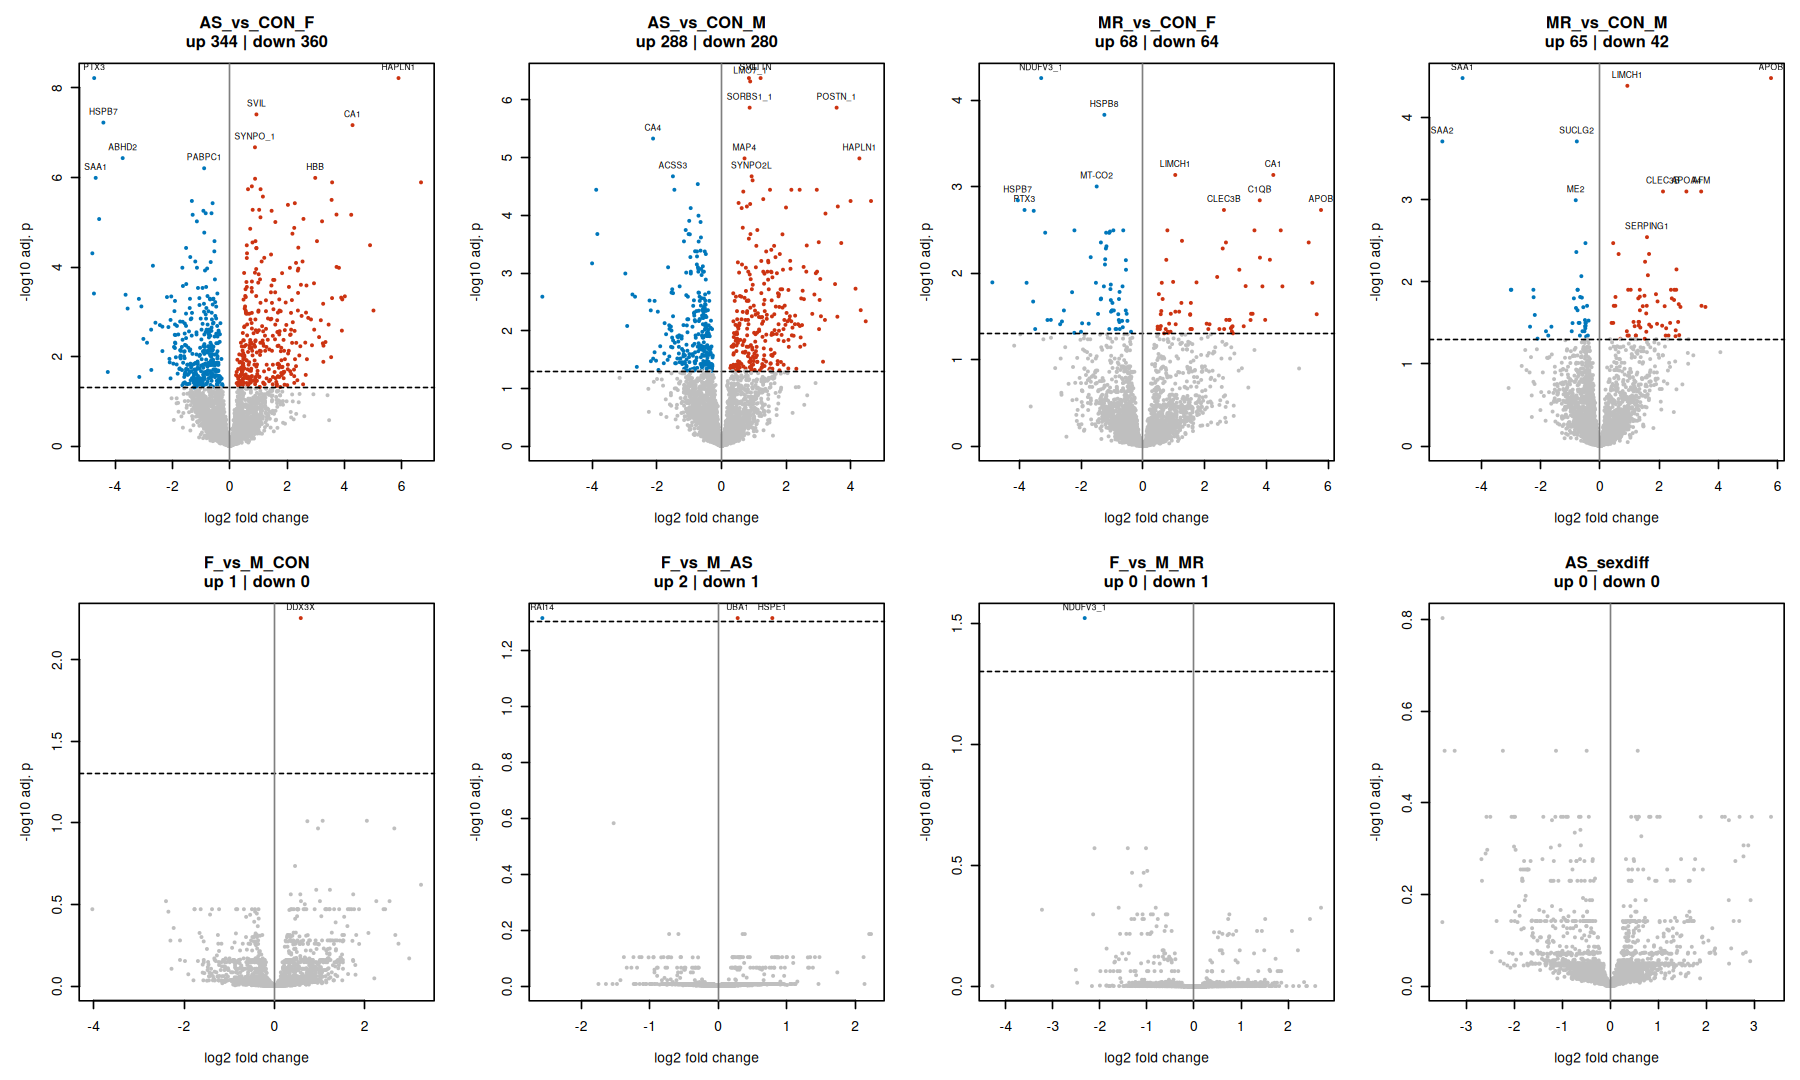

In [11]:
options(repr.plot.width = 15, repr.plot.height = 9)
par(mfrow = c(2, 4), mar = c(5, 5, 4, 1))
for (cn in c("AS_vs_CON_F", "AS_vs_CON_M", "MR_vs_CON_F", "MR_vs_CON_M",
             "F_vs_M_CON", "F_vs_M_AS", "F_vs_M_MR", "AS_sexdiff")) volcano(cn)
options(repr.plot.width = 12, repr.plot.height = 6)

### Top 15 proteins per group comparison

In [12]:
show_cols <- c("protein", "logFC", "AveExpr", "adj.P.Val", "imputed_in_groups")
for (cn in c("AS_vs_CON", "MR_vs_CON", "AS_vs_MR")) {
  cat("\n=====", cn, "=====\n")
  top <- head(res[[cn]][, show_cols], 15)
  top$logFC <- round(top$logFC, 2); top$AveExpr <- round(top$AveExpr, 1)
  top$adj.P.Val <- signif(top$adj.P.Val, 2)
  print(top, row.names = FALSE)
}


===== AS_vs_CON =====
  protein logFC AveExpr adj.P.Val imputed_in_groups
     SVIL  0.89    31.8   4.2e-13                 0
   HAPLN1  5.07    27.5   9.1e-13                 6
 SORBS1_1  0.88    34.1   1.5e-11                 0
  POSTN_1  3.56    34.2   1.5e-11                 0
  SYNPO_1  0.78    32.6   5.4e-11                 0
     CTTN  1.07    30.3   6.0e-11                 0
     MAP4  0.74    34.1   6.0e-11                 0
     SAA1 -4.28    25.6   1.2e-10                32
     PTX3 -3.48    25.1   1.6e-10                31
      CA1  3.41    32.1   2.9e-10                 0
 PPP1R12C  0.99    29.9   3.4e-10                 0
     SYNM  0.58    33.9   3.5e-10                 0
    BLVRB  0.98    32.2   3.5e-10                 0
  SYNPO2L  0.91    34.5   1.2e-09                 0
   CLEC3B  2.20    28.2   1.3e-09                 1

===== MR_vs_CON =====
  protein logFC AveExpr adj.P.Val imputed_in_groups
   LIMCH1  0.99    30.8   4.1e-08                 0
     APOB  5.77   

## 9. Sorting the hits as in the paper

### 9a. Shared, AS-specific, MR-specific, divergent

Rules from the paper's methods:
- **AS-specific**: significant in AS vs CON **and** in AS vs MR, same direction, and **not** significant in MR vs CON. (MR-specific analogous.)
- **Shared**: significant in both AS vs CON and MR vs CON, same direction.
- **Divergent**: significant in both vs CON, opposite directions.

Remember the caveat: "not significant in MR" partly reflects that MR has fewer patients (17 vs 41), so "AS-specific" means "clearly changed in AS, not demonstrably changed in MR".

**What "up" and "down" mean in the table below.** Every direction is relative to the **controls**:
- **shared** and **AS-specific**: direction in AS vs CON (for shared proteins it is the same in MR vs CON).
- **MR-specific**: direction in MR vs CON.
- **divergent**: these proteins go in *opposite* directions in the two diseases, so one word can't describe them. The column shows the direction **in AS vs CON**, and MR always goes the other way: **up = higher in AS and lower in MR** (both compared with controls), **down = lower in AS and higher in MR**. The second table below lists the divergent proteins with both directions spelled out.

In [13]:
s_as  <- dt[, "AS_vs_CON"]; s_mr <- dt[, "MR_vs_CON"]; s_am <- dt[, "AS_vs_MR"]
category <- rep(NA_character_, nrow(dt)); names(category) <- rownames(dt)
category[s_as != 0 & s_mr != 0 & s_as == s_mr] <- "shared"
category[s_as != 0 & s_mr != 0 & s_as != s_mr] <- "divergent"
category[s_as != 0 & s_mr == 0 & s_am == s_as] <- "AS-specific"
category[s_mr != 0 & s_as == 0 & s_am == -s_mr] <- "MR-specific"   # MR-CON up  <=>  AS-MR down

dir_lab <- ifelse(s_as != 0, ifelse(s_as > 0, "up", "down"), ifelse(s_mr > 0, "up", "down"))
cat_table <- table(category = category, direction = dir_lab, useNA = "no")
cat_table <- cbind(cat_table, total = rowSums(cat_table))
cat_table[c("shared", "AS-specific", "MR-specific", "divergent")[
  c("shared", "AS-specific", "MR-specific", "divergent") %in% rownames(cat_table)], , drop = FALSE]

,down,up,total
shared,140,198,338
AS-specific,144,143,287
MR-specific,57,16,73
divergent,3,1,4


In [14]:
cat_df <- data.frame(protein = names(category)[!is.na(category)],
                     category = category[!is.na(category)],
                     logFC_AS_vs_CON = round(res$AS_vs_CON[names(category)[!is.na(category)], "logFC"], 3),
                     logFC_MR_vs_CON = round(res$MR_vs_CON[names(category)[!is.na(category)], "logFC"], 3),
                     logFC_AS_vs_MR  = round(res$AS_vs_MR [names(category)[!is.na(category)], "logFC"], 3),
                     adjP_AS_vs_CON  = signif(res$AS_vs_CON[names(category)[!is.na(category)], "adj.P.Val"], 3),
                     adjP_MR_vs_CON  = signif(res$MR_vs_CON[names(category)[!is.na(category)], "adj.P.Val"], 3),
                     adjP_AS_vs_MR   = signif(res$AS_vs_MR [names(category)[!is.na(category)], "adj.P.Val"], 3))
cat_df <- cat_df[order(cat_df$category, cat_df$adjP_AS_vs_CON), ]

# divergent proteins: direction in each disease, both relative to controls
div <- cat_df[cat_df$category == "divergent", ]
div$AS_vs_CON <- ifelse(div$logFC_AS_vs_CON > 0, "up", "down")
div$MR_vs_CON <- ifelse(div$logFC_MR_vs_CON > 0, "up", "down")
div$label_in_table_above <- div$AS_vs_CON
cat("Divergent proteins (directions relative to controls):\n")
print(div[, c("protein", "AS_vs_CON", "MR_vs_CON", "label_in_table_above",
              "logFC_AS_vs_CON", "logFC_MR_vs_CON", "adjP_AS_vs_CON", "adjP_MR_vs_CON")],
      row.names = FALSE)

Divergent proteins (directions relative to controls):


 protein AS_vs_CON MR_vs_CON label_in_table_above logFC_AS_vs_CON logFC_MR_vs_CON adjP_AS_vs_CON adjP_MR_vs_CON
    STOM      down        up                 down          -0.287           0.281        0.00271        0.04220
 COL28A1      down        up                 down          -1.626           2.041        0.00935        0.02150
    TSPO        up      down                   up           0.677          -0.858        0.00944        0.02040
 ANKRD29      down        up                 down          -1.534           2.718        0.01420        0.00192


### 9b. Sex: significant in one sex only (paper's approach) vs formal interaction test

The paper looked at proteins significant vs control in **one sex only**. That compares "significant" with "not significant", which is strongly influenced by group size (e.g. 5 female vs 12 male MR patients). The **interaction contrast** (`AS_sexdiff`, `MR_sexdiff`) directly tests whether the disease effect differs between women and men, so it is the more reliable way to claim a sex-specific effect. Both are shown.

In [15]:
sex_split <- function(f_col, m_col, inter_col) {
  f <- dt[, f_col]; m <- dt[, m_col]; i <- dt[, inter_col]
  c(significant_in_both       = sum(f != 0 & m != 0),
    female_only               = sum(f != 0 & m == 0),
    male_only                 = sum(m != 0 & f == 0),
    interaction_significant   = sum(i != 0),
    female_only_AND_interaction = sum(f != 0 & m == 0 & i != 0),
    male_only_AND_interaction   = sum(m != 0 & f == 0 & i != 0))
}
sex_table <- rbind(AS = sex_split("AS_vs_CON_F", "AS_vs_CON_M", "AS_sexdiff"),
                   MR = sex_split("MR_vs_CON_F", "MR_vs_CON_M", "MR_sexdiff"))
t(sex_table)

,AS,MR
significant_in_both,290,32
female_only,414,100
male_only,278,75
interaction_significant,0,0
female_only_AND_interaction,0,0
male_only_AND_interaction,0,0


**Reading it.** `female_only` / `male_only` are the paper-style counts: several hundred proteins in AS look "sex-specific". But **not a single protein passes the interaction test** at adj. p < 0.05. So for these proteins the disease effect goes in the same direction in both sexes and is only significant in one of them, which is what you expect from noise and different group sizes. With this data, no protein shows a demonstrably *different* disease effect in women and men. The "female-only" and "male-only" lists are best described as "significant in women, not shown in men" (and vice versa), not as "sex-specific".

Also note in Section 8: female vs male **within** each group gives only 1–3 significant proteins. Sex differences in this cohort are small compared with the disease effects.

In [16]:
for (g in c("AS", "MR")) {
  r <- res[[paste0(g, "_sexdiff")]]
  sig <- r[r$direction != "ns", ]
  cat("\n=====", g, ": proteins whose disease effect differs between women and men =====\n")
  if (nrow(sig) == 0) { cat("none at adj. p < 0.05\n"); next }
  sig$logFC_F <- round(res[[paste0(g, "_vs_CON_F")]][rownames(sig), "logFC"], 2)
  sig$logFC_M <- round(res[[paste0(g, "_vs_CON_M")]][rownames(sig), "logFC"], 2)
  sig$adj.P.Val <- signif(sig$adj.P.Val, 2)
  print(head(sig[, c("protein", "logFC_F", "logFC_M", "adj.P.Val", "imputed_in_groups")], 20),
        row.names = FALSE)
}


===== AS : proteins whose disease effect differs between women and men =====
none at adj. p < 0.05

===== MR : proteins whose disease effect differs between women and men =====
none at adj. p < 0.05


## 10. Sensitivity checks

### 10a. Unequal group variances: `arrayWeights`

Section 4 showed (diagnosis) **that** the groups differ in variance. But the main model in Sections 7–9 still assumes equal variance in all groups: it uses one pooled variance per protein, whatever the boxplots show. This section checks **whether that assumption changes the results** (consequence).

`arrayWeights(..., var.group = cell)` estimates one weight per subgroup: noisier groups get weight < 1 (they count less), calmer groups > 1 (they count more). The model is refitted with these weights, and the table compares the number of significant proteins **without weights (main analysis)** and **with weights**:
- `equal_variance`: main analysis (Sections 7–9)
- `with_weights`: same model, group-specific weights
- `difference`: with_weights − equal_variance
- `found_in_both`: significant in both, same direction
- `only_equal_var` / `only_weighted`: significant in only one of the two analyses

In [17]:
w <- arrayWeights(expr, design, var.group = info$cell)
cat("Estimated weight per subgroup (1 = average; < 1 = noisier):\n")
print(round(tapply(w, info$cell, unique), 2))

fit_w  <- eBayes(contrasts.fit(lmFit(expr, design, weights = w), cm), trend = TRUE)
dt_w   <- as_mat(decideTests(fit_w, method = "separate", adjust.method = "BH", p.value = FDR_CUTOFF))

overlap <- function(a, b) colSums(a != 0 & b != 0 & a == b)
weights_cmp <- data.frame(contrast       = colnames(dt),
                          equal_variance = colSums(dt != 0),
                          with_weights   = colSums(dt_w != 0),
                          row.names = NULL)
weights_cmp$difference     <- weights_cmp$with_weights - weights_cmp$equal_variance
weights_cmp$found_in_both  <- overlap(dt, dt_w)
weights_cmp$only_equal_var <- weights_cmp$equal_variance - weights_cmp$found_in_both
weights_cmp$only_weighted  <- weights_cmp$with_weights - weights_cmp$found_in_both
weights_cmp

Estimated weight per subgroup (1 = average; < 1 = noisier):


CON_F CON_M  AS_F  AS_M  MR_F  MR_M 
 1.28  1.32  0.84  0.99  0.89  0.98 


contrast,equal_variance,with_weights,difference,found_in_both,only_equal_var,only_weighted
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
AS_vs_CON,1283,1442,159,1283,0,159
MR_vs_CON,471,543,72,471,0,72
AS_vs_MR,535,475,-60,475,60,0
AS_vs_CON_F,704,828,124,704,0,124
AS_vs_CON_M,568,789,221,568,0,221
MR_vs_CON_F,132,145,13,131,1,14
MR_vs_CON_M,107,227,120,107,0,120
F_vs_M_CON,1,7,6,1,0,6
F_vs_M_AS,3,0,-3,0,3,0


**Reading it.** This table is where you see the effect of acknowledging the unequal variances.
- Controls get weight ~1.3, AS women ~0.84, i.e. the calm control group now counts more and the noisy AS group less.
- Most counts **go up**: AS vs CON from 1,283 to 1,442, MR women vs controls 132 → 145, MR men vs controls roughly doubles (107 → 227). Comparisons that include the control group gain most, because their precision was underestimated when the controls' small variance was pooled with the larger AS variance.
- AS vs MR **goes down** slightly (535 → 475): it compares the two noisier groups, which now count less.
- Most proteins from the main analysis are found again (`found_in_both`); the changes are mostly additional hits, not different ones.
- The interaction (sex × disease) contrasts stay at about 0, so the conclusion about sex does not change.

So the equal-variance assumption does matter for the exact numbers, even though the overall picture stays the same.

### 10b. Without imputation

limma can work with missing values (it uses the values that are there). Here the same model is fitted on the matrix **before imputation** (sheet `not_imputed`). Proteins that are rarely seen get fewer degrees of freedom instead of invented values. Large differences from the imputed analysis point to hits that mainly come from imputation (typically proteins mostly missing in one group).

In [18]:
ni <- as.data.frame(read_excel(DATA_FILE, sheet = "not_imputed"))
expr_ni <- as.matrix(ni[, samples]); rownames(expr_ni) <- label

# contrasts need every involved cell to have at least 2 values; otherwise limma returns NA
fit_ni <- suppressWarnings(eBayes(contrasts.fit(lmFit(expr_ni, design), cm), trend = TRUE))
dt_ni  <- as_mat(decideTests(fit_ni, method = "separate", adjust.method = "BH", p.value = FDR_CUTOFF))
dt_ni[is.na(dt_ni)] <- 0

sens <- data.frame(contrast       = colnames(dt),
                   imputed        = colSums(dt != 0),
                   not_imputed    = colSums(dt_ni != 0),
                   shared_imp_vs_notimp = overlap(dt, dt_ni),
                   row.names = NULL)
sens

contrast,imputed,not_imputed,shared_imp_vs_notimp
<chr>,<dbl>,<dbl>,<dbl>
AS_vs_CON,1283,1217,1121
MR_vs_CON,471,455,404
AS_vs_MR,535,509,448
AS_vs_CON_F,704,671,599
AS_vs_CON_M,568,545,482
MR_vs_CON_F,132,115,102
MR_vs_CON_M,107,98,88
F_vs_M_CON,1,2,1
F_vs_M_AS,3,3,2


**Reading it.** `shared_imp_vs_notimp` counts proteins significant in the same direction in both analyses: these are the most robust hits. Proteins only significant with imputation should be interpreted with care.

Counts drop a little without imputation; most hits (e.g. ~1,100 of ~1,280 for AS vs CON) are found either way.

## 11. Summary: how many proteins differ?

In [19]:
cat("=== Significant proteins (adj. p < 0.05, BH per contrast; limma-trend, imputed data) ===\n\n")
print(counts[, c("family", "contrast", "up", "down", "total")], row.names = FALSE)

cat("\n=== Disease groups: paper-style categories ===\n")
cat("(up/down relative to controls; divergent: direction in AS, MR goes the opposite way)\n")
print(cat_table)

cat("\n=== Sex: one-sex-only (paper style) vs formal interaction test ===\n")
print(t(sex_table))

cat("\nFor comparison, the paper reported: AS vs CON 1,332 | MR vs CON 400 | AS vs MR 903;",
    "\nshared 270, AS-specific 518, MR-specific 79, divergent 5;",
    "\nfemale AS 468 | male AS 229 | female MR 95 | male MR 102.\n")

=== Significant proteins (adj. p < 0.05, BH per contrast; limma-trend, imputed data) ===



                        family    contrast  up down total
                        groups   AS_vs_CON 560  723  1283
                        groups   MR_vs_CON 237  234   471
                        groups    AS_vs_MR 296  239   535
 disease vs control within sex AS_vs_CON_F 344  360   704
 disease vs control within sex AS_vs_CON_M 288  280   568
 disease vs control within sex MR_vs_CON_F  68   64   132
 disease vs control within sex MR_vs_CON_M  65   42   107
   female vs male within group  F_vs_M_CON   1    0     1
   female vs male within group   F_vs_M_AS   2    1     3
   female vs male within group   F_vs_M_MR   0    1     1
   interaction (sex x disease)  AS_sexdiff   0    0     0
   interaction (sex x disease)  MR_sexdiff   0    0     0



=== Disease groups: paper-style categories ===


(up/down relative to controls; divergent: direction in AS, MR goes the opposite way)


            down  up total
AS-specific  144 143   287
MR-specific   57  16    73
divergent      3   1     4
shared       140 198   338



=== Sex: one-sex-only (paper style) vs formal interaction test ===


                             AS  MR
significant_in_both         290  32
female_only                 414 100
male_only                   278  75
interaction_significant       0   0
female_only_AND_interaction   0   0
male_only_AND_interaction     0   0



For comparison, the paper reported: AS vs CON 1,332 | MR vs CON 400 | AS vs MR 903; 
shared 270, AS-specific 518, MR-specific 79, divergent 5; 
female AS 468 | male AS 229 | female MR 95 | male MR 102.


### Why the numbers differ from the paper

The pipeline follows the paper's statistics (limma-trend, eBayes, BH, adj. p < 0.05), but the input is not identical:
- **Filtering**: ≥ 60 % valid values in at least one group here, ≥ 50 % in the paper, so the protein list differs.
- **Normalization**: an extra median normalization was applied in the QC notebook.
- **Imputation**: random draws, so every imputation gives slightly different values (and slightly different hits).
- **Design**: group comparisons here are averaged over sex (balanced), the paper's exact design is not stated.

The overall pattern is what to compare, not the exact numbers.

### Take-home
- **Groups:** AS differs from controls in about 1,280 proteins (a third of the proteome, more down than up), MR in about 470, AS vs MR in about 540. Same order as the paper (1,332 / 400 / 903); AS vs MR is lower, partly because our group comparisons are balanced for sex and the MR group has only 5 women.
- **Paper-style categories:** about 340 shared, 290 AS-specific, 70 MR-specific and 4 divergent proteins. The paper reports more AS-specific proteins mainly because it found more AS vs MR differences, which the AS-specific rule requires.
- **Sexes:** within each group, women and men differ in only 1–3 proteins. Disease vs control within each sex gives the paper-like picture (more hits in female AS than in male AS), but the formal interaction test finds **no** protein whose disease effect differs between the sexes. The "one-sex-only" lists therefore mostly reflect statistical power, not biology.
- **Variance:** AS (and to a lesser extent MR) is clearly more variable than controls. Accounting for it with weights changes the counts noticeably, which is worth mentioning when comparing with the paper.